# Actividad 1.2 · Aprendizaje supervisado: SVM y red neuronal
**Maestría en Inteligencia Artificial · TecNM Virtual** — Aprendizaje Automático Avanzado, Unidad 1  
**Autores:** Arturo Pérez y María D. Camacho · **Fecha:** octubre de 2026 · **Versión del modelo:** v1.0  
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/artperezg/AA_Actividad1.2_Paradigmas/blob/main/notebooks/01_supervisado_SVM_y_RedNeuronal.ipynb)

**Caso de estudio:** predecir si un paciente tiene enfermedad coronaria a partir de 13 variables clínicas.

| Punto de la actividad | Sección |
|---|---|
| Tarea 2 · Selección del caso de estudio y dataset | 1 |
| Tarea 3a · Preparación de datos (limpieza, estandarización, train/test) y pipeline documentado | 2 |
| Tarea 3b · Entrenamiento de al menos dos modelos (SVM y red neuronal) | 3 |
| Tarea 3c · Evaluación (exactitud, precisión, recall, F1 y matriz de confusión) | 4 |
| Tarea 6 · Evidencias: calidad de los datos, sesgo, varianza y sobreajuste | 5 |

In [1]:
# Configuración: en Colab descarga el proyecto desde GitHub (no requiere Google Drive)
import sys, warnings, zipfile
from pathlib import Path

REPO_URL = "https://github.com/artperezg/AA_Actividad1.2_Paradigmas.git"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/AA_Actividad1.2_Paradigmas")
    if not RAIZ.exists():
        import subprocess
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(RAIZ)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("No se pudo descargar el repositorio:\n" + r.stderr)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW, DATA_PROC = RAIZ / "data" / "raw", RAIZ / "data" / "processed"
DATA_PROC.mkdir(parents=True, exist_ok=True)
RESULTADOS = RAIZ / "resultados" / "01_supervisado"
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(parents=True, exist_ok=True)
SEMILLA, VERSION_MODELO = 42, "v1.0"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /content/AA_Actividad1.2_Paradigmas


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, validation_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # algunas configuraciones de la búsqueda no convergen
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def guardar_figura(nombre):
    ruta = RESULTADOS / f"{nombre}.png"
    plt.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(RAIZ))
COLORES = {"SVM": "#1f6fb2", "Red neuronal": "#e07b39"}

## 1. Tarea 2 · Caso de estudio y dataset
**Dataset:** *Heart Disease* (Cleveland), UCI Machine Learning Repository, id 45 (Janosi et al., 1989). Se usa el archivo `processed.cleveland.data` del ZIP original (en `data/raw/`); el propio ZIP indica que el archivo crudo `cleveland.data` está dañado.

**Relevancia:** las enfermedades cardiovasculares son la principal causa de muerte en el mundo. Un clasificador con datos clínicos rutinarios puede apoyar la decisión de enviar a un paciente a angiografía. Un falso negativo es el error más costoso.

**Variables:** 303 pacientes, 13 características y 1 variable objetivo.

| Variable | Descripción | Tipo |
|---|---|---|
| `age`, `trestbps`, `chol`, `thalach`, `oldpeak` | Edad, presión arterial en reposo, colesterol, frecuencia cardíaca máxima, depresión del segmento ST | Numéricas |
| `ca` | Número de vasos principales coloreados por fluoroscopía (0–3) | Numérica discreta |
| `cp`, `restecg`, `slope`, `thal` | Tipo de dolor torácico, electrocardiograma en reposo, pendiente del segmento ST, prueba de talio | Categóricas |
| `sex`, `fbs`, `exang` | Sexo, glucosa en ayunas > 120 mg/dl, angina inducida por ejercicio | Binarias |
| `num` | **Objetivo:** diagnóstico angiográfico (0 = sin enfermedad; 1–4 = con enfermedad) | Ordinal |

In [3]:
if not (DATA_RAW / "processed.cleveland.data").exists():          # se extrae del ZIP original si hace falta
    with zipfile.ZipFile(DATA_RAW / "heart_disease.zip") as z:
        z.extract("processed.cleveland.data", DATA_RAW)

COLUMNAS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(DATA_RAW / "processed.cleveland.data", header=None, names=COLUMNAS, na_values="?")  # "?" = faltante

VARS_NUMERICAS   = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
VARS_CATEGORICAS = ["cp", "restecg", "slope", "thal"]
VARS_BINARIAS    = ["sex", "fbs", "exang"]
print(f"Registros: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Registros: 303 | Columnas: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Tarea 3a · Preparación de datos
### 2.1 Inspección: faltantes, duplicados y atípicos

In [4]:
calidad = pd.DataFrame({"faltantes": df.isna().sum(), "mínimo": df.min(), "máximo": df.max()})
print("Registros duplicados:", df.duplicated().sum())
print("Celdas faltantes:", int(df.isna().sum().sum()), "en", int(df.isna().any(axis=1).sum()), "registros")

# Atípicos con la regla de Tukey (fuera de Q1 - 1.5·RIC y Q3 + 1.5·RIC)
atipicos = {}
for var in VARS_NUMERICAS:
    q1, q3 = df[var].quantile([0.25, 0.75]); ric = q3 - q1
    atipicos[var] = int(((df[var] < q1 - 1.5 * ric) | (df[var] > q3 + 1.5 * ric)).sum())
calidad["atípicos (Tukey)"] = pd.Series(atipicos, dtype="Int64")
calidad.astype("object").fillna("—")

Registros duplicados: 0
Celdas faltantes: 6 en 6 registros


,faltantes,mínimo,máximo,atípicos (Tukey)
age,0,29.0,77.0,0
sex,0,0.0,1.0,—
cp,0,1.0,4.0,—
trestbps,0,94.0,200.0,9
chol,0,126.0,564.0,5
fbs,0,0.0,1.0,—
restecg,0,0.0,2.0,—
thalach,0,71.0,202.0,1
exang,0,0.0,1.0,—
oldpeak,0,0.0,6.2,5


**Hallazgos:** 6 valores faltantes (4 en `ca`, 2 en `thal`), sin duplicados. Los atípicos (por ejemplo, colesterol de 564 mg/dl) son clínicamente posibles, así que **se conservan**; su efecto se controla con la estandarización.

### 2.2 Variable objetivo
Se binariza `num` (0 = sin enfermedad, 1–4 = con enfermedad), como indica la documentación de UCI para esta base.

Figura guardada: resultados/01_supervisado/01_distribucion_objetivo.png


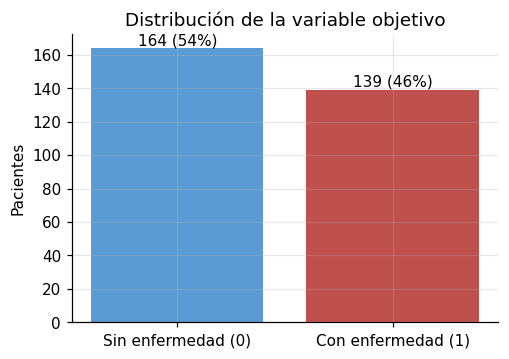

In [5]:
df["diagnostico"] = (df["num"] > 0).astype(int)
conteo = df["diagnostico"].value_counts().sort_index()
plt.figure(figsize=(5, 3.4))
plt.bar(["Sin enfermedad (0)", "Con enfermedad (1)"], conteo.values, color=["#5b9bd5", "#c0504d"])
for i, v in enumerate(conteo.values):
    plt.text(i, v + 2, f"{v} ({v / len(df):.0%})", ha="center")
plt.title("Distribución de la variable objetivo"); plt.ylabel("Pacientes")
guardar_figura("01_distribucion_objetivo")
plt.show()

### 2.3 Pipeline de preparación

| Paso | Técnica | Por qué | Impacto en el modelo |
|---|---|---|---|
| 1. División train/test | 75 % / 25 %, estratificada, semilla 42 | Evaluar con datos no vistos y conservar la proporción de clases | Estimación honesta de la generalización |
| 2. Limpieza | Imputación: mediana (numéricas) y moda (categóricas), ajustada solo con entrenamiento | Solo 2 % de registros incompletos; no conviene perder pacientes | Se conservan los 303 registros sin fuga de información |
| 3. Codificación | One-hot para `cp`, `restecg`, `slope` y `thal` | Son categorías sin orden numérico | Evita distancias falsas entre categorías |
| 4. Estandarización | *z-score* en variables numéricas | El SVM usa distancias y la red neuronal, gradientes | Ninguna variable domina por su escala |

Los pasos 2–4 van dentro de un `Pipeline`, que se reajusta solo con entrenamiento en cada pliegue de la validación cruzada.

In [6]:
X = df[VARS_NUMERICAS + VARS_CATEGORICAS + VARS_BINARIAS]
y = df["diagnostico"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputacion", SimpleImputer(strategy="median")), ("escalamiento", StandardScaler())]), VARS_NUMERICAS),
    ("cat", Pipeline([("imputacion", SimpleImputer(strategy="most_frequent")),
                      ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), VARS_CATEGORICAS),
    ("bin", "passthrough", VARS_BINARIAS),
], verbose_feature_names_out=False)

print(f"Entrenamiento: {len(X_train)} pacientes | Prueba: {len(X_test)} pacientes")
print(f"Proporción con enfermedad — entrenamiento: {y_train.mean():.3f} | prueba: {y_test.mean():.3f}")

Entrenamiento: 227 pacientes | Prueba: 76 pacientes
Proporción con enfermedad — entrenamiento: 0.458 | prueba: 0.461


In [7]:
# Datos procesados (data/processed/)
imputador = ColumnTransformer([("num", SimpleImputer(strategy="median"), VARS_NUMERICAS),
                               ("cat", SimpleImputer(strategy="most_frequent"), VARS_CATEGORICAS)],
                              remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
imputador.fit(X_train)                                   # estadísticos de imputación solo con entrenamiento
limpio = pd.concat([imputador.transform(X_train).assign(conjunto="entrenamiento"),
                    imputador.transform(X_test).assign(conjunto="prueba")])
limpio[COLUMNAS[:-1] + ["conjunto"]].join(y).sort_index().to_csv(DATA_PROC / "heart_disease_limpio.csv", index_label="id_paciente")

prep = clone(preprocesador).fit(X_train)
nombres = prep.get_feature_names_out()
pd.DataFrame(prep.transform(X_train), columns=nombres, index=X_train.index).join(y_train) \
  .to_csv(DATA_PROC / "heart_train_transformado.csv", index_label="id_paciente")
pd.DataFrame(prep.transform(X_test), columns=nombres, index=X_test.index).join(y_test) \
  .to_csv(DATA_PROC / "heart_test_transformado.csv", index_label="id_paciente")
print("Guardados en data/processed/:", sorted(p.name for p in DATA_PROC.glob("heart*")))
print("Características después de la preparación:", len(nombres))

Guardados en data/processed/: ['heart_disease_limpio.csv', 'heart_test_transformado.csv', 'heart_train_transformado.csv']
Características después de la preparación: 22


## 3. Tarea 3b · Entrenamiento de modelos
Los hiperparámetros de cada modelo se eligen con **validación cruzada estratificada de 5 pliegues** sobre el entrenamiento, con criterio F1.

### 3.1 Máquina de vectores de soporte (SVM)
Busca el hiperplano de margen máximo; con kernel RBF separa clases no lineales. Se prueban kernel lineal y RBF, $C$ y $\gamma$.

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

svm = Pipeline([("preparacion", clone(preprocesador)), ("modelo", SVC(random_state=SEMILLA))])
rejilla_svm = [{"modelo__kernel": ["linear"], "modelo__C": [0.01, 0.1, 1, 10, 100]},
               {"modelo__kernel": ["rbf"], "modelo__C": [0.01, 0.1, 1, 10, 100],
                "modelo__gamma": ["scale", 0.001, 0.01, 0.1, 1]}]
busqueda_svm = GridSearchCV(svm, rejilla_svm, cv=CV, scoring="f1", n_jobs=-1).fit(X_train, y_train)
svm_final = busqueda_svm.best_estimator_
f1_cv_svm = (busqueda_svm.best_score_, busqueda_svm.cv_results_["std_test_score"][busqueda_svm.best_index_])
print("Mejores hiperparámetros:", busqueda_svm.best_params_)
print(f"F1 en validación cruzada: {f1_cv_svm[0]:.3f} ± {f1_cv_svm[1]:.3f}")

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
F1 en validación cruzada: 0.807 ± 0.056


### 3.2 Red neuronal (perceptrón multicapa)
Capas ocultas con activación ReLU, entrenadas con Adam minimizando la entropía cruzada con regularización L2 ($\alpha$). Se prueban arquitectura, $\alpha$ y tasa de aprendizaje.

In [9]:
red = Pipeline([("preparacion", clone(preprocesador)), ("modelo", MLPClassifier(max_iter=2000, random_state=SEMILLA))])
rejilla_red = {"modelo__hidden_layer_sizes": [(8,), (16,), (32, 16), (64, 32)],
               "modelo__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 3.0, 10.0],
               "modelo__learning_rate_init": [0.001, 0.01]}
busqueda_red = GridSearchCV(red, rejilla_red, cv=CV, scoring="f1", n_jobs=-1).fit(X_train, y_train)   # ≈ 1–2 min
red_final = busqueda_red.best_estimator_
f1_cv_red = (busqueda_red.best_score_, busqueda_red.cv_results_["std_test_score"][busqueda_red.best_index_])
print("Mejores hiperparámetros:", busqueda_red.best_params_)
print(f"F1 en validación cruzada: {f1_cv_red[0]:.3f} ± {f1_cv_red[1]:.3f}")

Mejores hiperparámetros: {'modelo__alpha': 3.0, 'modelo__hidden_layer_sizes': (8,), 'modelo__learning_rate_init': 0.001}
F1 en validación cruzada: 0.800 ± 0.047


## 4. Tarea 3c · Evaluación en el conjunto de prueba (76 pacientes)

In [10]:
def metricas(modelo, X_, y_):
    p = modelo.predict(X_)
    return {"Exactitud": accuracy_score(y_, p), "Precisión": precision_score(y_, p),
            "Recall": recall_score(y_, p), "F1": f1_score(y_, p)}

tabla = pd.DataFrame({"SVM": metricas(svm_final, X_test, y_test),
                      "Red neuronal": metricas(red_final, X_test, y_test)}).T
tabla["F1 validación cruzada"] = [f"{f1_cv_svm[0]:.3f} ± {f1_cv_svm[1]:.3f}", f"{f1_cv_red[0]:.3f} ± {f1_cv_red[1]:.3f}"]
tabla.round(3).to_csv(RESULTADOS / "metricas_modelos.csv")
tabla.round(3)

,Exactitud,Precisión,Recall,F1,F1 validación cruzada
SVM,0.882,0.882,0.857,0.870,0.807 ± 0.056
Red neuronal,0.855,0.816,0.886,0.849,0.800 ± 0.047


SVM: VN=37, FP=4, FN=5, VP=30
Red neuronal: VN=34, FP=7, FN=4, VP=31
Figura guardada: resultados/01_supervisado/02_matrices_confusion.png


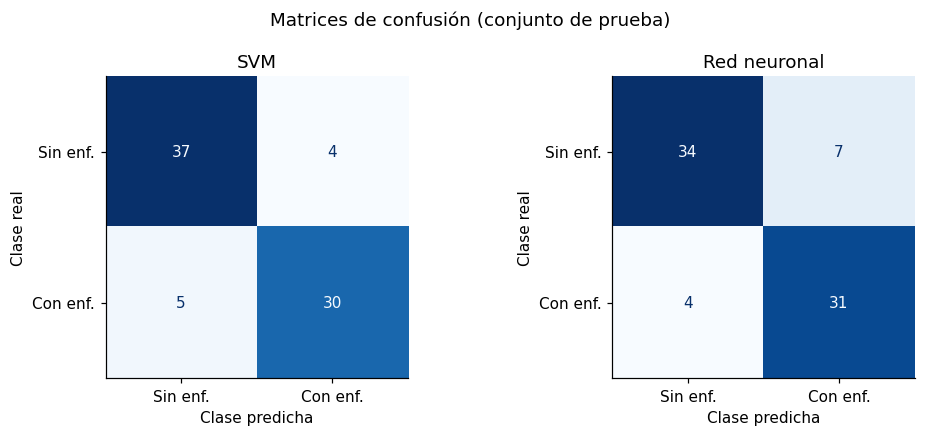

Modelos guardados en resultados/01_supervisado/modelos/


In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (nombre, modelo) in zip(ejes, [("SVM", svm_final), ("Red neuronal", red_final)]):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, display_labels=["Sin enf.", "Con enf."],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre); ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.grid(False)
    vn, fp, fn, vp = confusion_matrix(y_test, modelo.predict(X_test)).ravel()
    print(f"{nombre}: VN={vn}, FP={fp}, FN={fn}, VP={vp}")
plt.suptitle("Matrices de confusión (conjunto de prueba)")
plt.tight_layout()
guardar_figura("02_matrices_confusion")
plt.show()

joblib.dump(svm_final, MODELOS / f"svm_{VERSION_MODELO}.joblib")
joblib.dump(red_final, MODELOS / f"red_neuronal_{VERSION_MODELO}.joblib")
print("Modelos guardados en resultados/01_supervisado/modelos/")

**Resultados**
- **SVM** (kernel RBF, C = 1, γ = 0.01): exactitud de 0.882 y F1 de 0.870. Detecta a 30 de los 35 enfermos (5 falsos negativos).
- **Red neuronal** (8 neuronas, α = 3): exactitud de 0.855 y F1 de 0.849. Tiene el mayor *recall* (0.886, 4 falsos negativos) a cambio de más falsos positivos (7).
- En validación cruzada ambos son prácticamente equivalentes (F1 de 0.807 y 0.800). **Modelo elegido para la versión v1.0: SVM**, por su mayor exactitud y precisión.

## 5. Tarea 6 · Evidencias para el análisis comparativo
### 5.1 Influencia de la calidad de los datos
Con los mismos hiperparámetros óptimos, se entrena cada modelo con tres niveles de preparación: **A** solo imputación, **B** imputación + estandarización (sin one-hot) y **C** pipeline completo.

Figura guardada: resultados/01_supervisado/03_calidad_datos.png


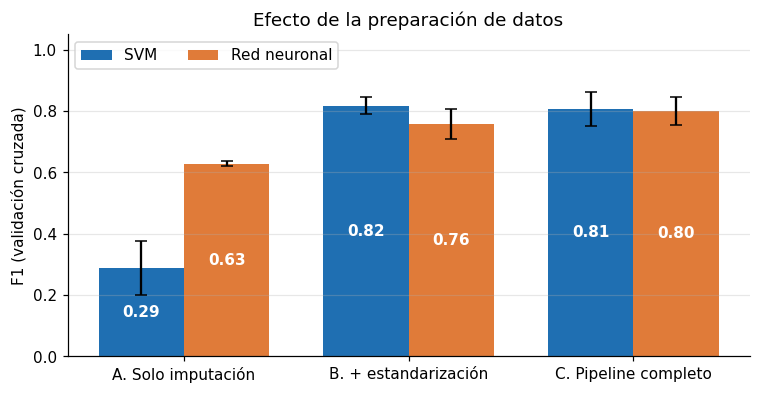

,Preparación,Modelo,F1 val. cruzada,desv.,F1 prueba,% predichos enfermos
0,A. Solo imputación,SVM,0.288,0.088,0.353,21.053
1,A. Solo imputación,Red neuronal,0.628,0.008,0.631,100.000
2,B. + estandarización,SVM,0.818,0.027,0.829,46.053
3,B. + estandarización,Red neuronal,0.757,0.049,0.822,50.000
4,C. Pipeline completo,SVM,0.807,0.056,0.870,44.737
5,C. Pipeline completo,Red neuronal,0.800,0.047,0.849,50.000


In [12]:
def variante(nombre):
    if nombre.startswith("A"):
        return ColumnTransformer([("num", SimpleImputer(strategy="median"), VARS_NUMERICAS),
                                  ("cat", SimpleImputer(strategy="most_frequent"), VARS_CATEGORICAS),
                                  ("bin", "passthrough", VARS_BINARIAS)])
    if nombre.startswith("B"):
        return ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median")), ("e", StandardScaler())]), VARS_NUMERICAS),
                                  ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("e", StandardScaler())]), VARS_CATEGORICAS),
                                  ("bin", "passthrough", VARS_BINARIAS)])
    return clone(preprocesador)

VARIANTES = ["A. Solo imputación", "B. + estandarización", "C. Pipeline completo"]
filas = []
for v in VARIANTES:
    for nombre, modelo in [("SVM", svm_final), ("Red neuronal", red_final)]:
        pipe = Pipeline([("preparacion", variante(v)), ("modelo", clone(modelo.named_steps["modelo"]))])
        f1 = cross_validate(pipe, X_train, y_train, cv=CV, scoring="f1")["test_score"]
        pred = pipe.fit(X_train, y_train).predict(X_test)
        filas.append({"Preparación": v, "Modelo": nombre, "F1 val. cruzada": f1.mean(), "desv.": f1.std(),
                      "F1 prueba": f1_score(y_test, pred), "% predichos enfermos": 100 * pred.mean()})
ablacion = pd.DataFrame(filas).round(3)
ablacion.to_csv(RESULTADOS / "experimento_calidad_datos.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(VARIANTES))
for i, nombre in enumerate(["SVM", "Red neuronal"]):
    sub = ablacion[ablacion["Modelo"] == nombre]
    barras = ax.bar(x + (i - 0.5) * 0.38, sub["F1 val. cruzada"], 0.38, yerr=sub["desv."], capsize=4,
                    color=COLORES[nombre], label=nombre)
    ax.bar_label(barras, fmt="%.2f", label_type="center", color="white", fontweight="bold")
ax.set_xticks(x, VARIANTES); ax.set_ylim(0, 1.05); ax.set_ylabel("F1 (validación cruzada)")
ax.set_title("Efecto de la preparación de datos"); ax.legend(loc="upper left", ncol=2); ax.grid(axis="x", visible=False)
guardar_figura("03_calidad_datos")
plt.show()
ablacion

**Resultado:** con el mismo modelo, la preparación cambia el F1 del SVM de 0.29 a 0.81.
- **A, sin estandarizar:** las variables de mayor escala (`chol`, `thalach`) dominan las distancias del SVM, y la red neuronal predice "enfermo" para el 100 % de los pacientes.
- **B, con estandarización:** es el paso decisivo para ambos modelos.
- **C, con one-hot:** mejora a la red neuronal (0.76 → 0.80). En el SVM la diferencia queda dentro de la variación entre pliegues.

### 5.2 Sesgo, varianza y sobreajuste
Se compara el desempeño en entrenamiento y en prueba, incluyendo una red **sin regularizar** (64 y 32 neuronas, $\alpha = 10^{-4}$), y se trazan curvas de validación al variar la complejidad.

In [13]:
red_sin_regularizar = Pipeline([("preparacion", clone(preprocesador)),
                                ("modelo", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, max_iter=2000,
                                                         random_state=SEMILLA))]).fit(X_train, y_train)
brecha = pd.DataFrame({nombre: {"F1 entrenamiento": metricas(m, X_train, y_train)["F1"],
                                "F1 prueba": metricas(m, X_test, y_test)["F1"]}
                       for nombre, m in [("SVM", svm_final), ("Red neuronal", red_final),
                                         ("Red sin regularizar", red_sin_regularizar)]}).T
brecha["Brecha"] = brecha["F1 entrenamiento"] - brecha["F1 prueba"]
brecha.round(3).to_csv(RESULTADOS / "brecha_entrenamiento_prueba.csv")
brecha.round(3)

,F1 entrenamiento,F1 prueba,Brecha
SVM,0.833,0.870,-0.036
Red neuronal,0.828,0.849,-0.021
Red sin regularizar,1.000,0.773,0.227


Figura guardada: resultados/01_supervisado/04_curvas_validacion.png


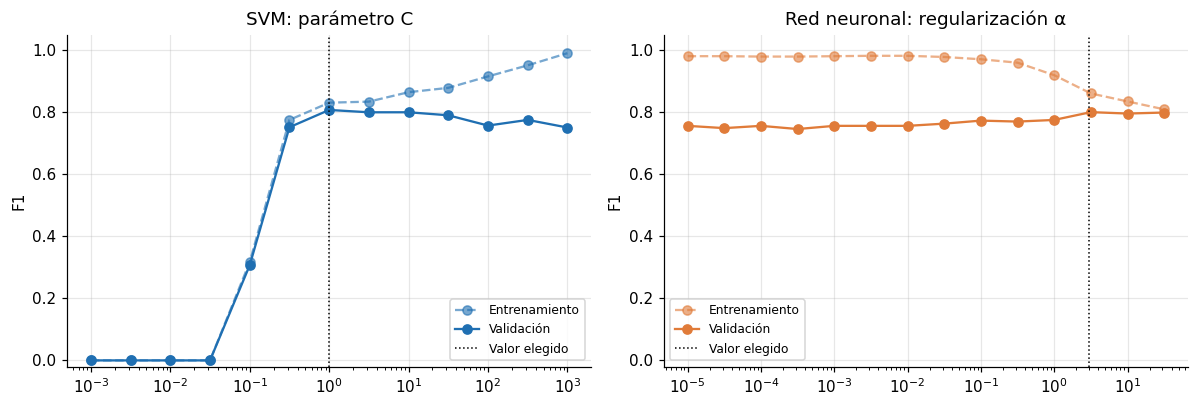

In [14]:
curvas = [("SVM: parámetro C", svm_final, "modelo__C", np.logspace(-3, 3, 13), COLORES["SVM"]),
          ("Red neuronal: regularización α", red_final, "modelo__alpha", np.logspace(-5, 1.5, 14), COLORES["Red neuronal"])]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (titulo, modelo, parametro, rango, color) in zip(ejes, curvas):
    f1_tr, f1_va = validation_curve(clone(modelo), X_train, y_train, param_name=parametro,
                                    param_range=rango, cv=CV, scoring="f1", n_jobs=-1)
    ax.plot(rango, f1_tr.mean(1), "o--", color=color, alpha=0.6, label="Entrenamiento")
    ax.plot(rango, f1_va.mean(1), "o-", color=color, label="Validación")
    ax.axvline(modelo.get_params()[parametro], color="k", ls=":", lw=1, label="Valor elegido")
    ax.set_xscale("log"); ax.set_ylim(-0.02, 1.05); ax.set_title(titulo); ax.set_ylabel("F1")
    ax.legend(fontsize=8, loc="lower right" if "SVM" in titulo else "lower left")
plt.tight_layout()
guardar_figura("04_curvas_validacion")
plt.show()

| Evidencia | Observación | Diagnóstico |
|---|---|---|
| Red sin regularizar | F1 de 1.000 en entrenamiento y 0.773 en prueba (brecha de 0.23) | **Sobreajuste (varianza alta)** |
| SVM con C ≤ 0.03 | F1 = 0 en entrenamiento y validación: clasifica a todos como sanos | **Sesgo alto (subajuste)** |
| SVM con C ≥ 100 | El F1 de entrenamiento sube hacia 0.99 y el de validación baja a ≈ 0.75 | **Varianza alta** |
| Red neuronal con α pequeño | F1 ≈ 0.98 en entrenamiento y ≈ 0.75 en validación | **Varianza alta** |
| SVM y red neuronal finales | Entrenamiento y prueba casi iguales (diferencia menor a 0.04) | **Equilibrio entre sesgo y varianza** |

In [15]:
import sklearn, platform
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.3 | scikit-learn 1.8.0 | pandas 3.0.2 | numpy 2.4.4
